In [5]:

from google.colab import drive
from pathlib import Path
import torch

# Connect Google Drive
drive.mount('/content/drive')

# Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [6]:

import json
import pandas as pd

# Project directories
ROOT = Path("/content/drive/MyDrive")

C1_DIR = ROOT / "Plant_Disease_HW2_C2"
C2_DIR = ROOT / "C2_Final_Deliverables"

CONFIG_DIR = C1_DIR / "config"
TEST_DIR = C1_DIR / "prepared_data/plantdoc_test"
SPLITS_DIR = C1_DIR / "splits"
CHECKPOINT_DIR = C2_DIR / "checkpoints"

# Load class mapping
with open(CONFIG_DIR / "class_to_idx.json", "r") as f:
    class_to_idx = json.load(f)

# Load PlantDoc test split
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

# Display dataset information
print("Number of classes:", len(class_to_idx))
print("Number of test records:", len(test_df))

print("\nClass mapping:")
for name, idx in sorted(
    class_to_idx.items(), key=lambda x: x[1]
):
    print(f"{idx}: {name}")

print("\nTest CSV columns:")
print(test_df.columns.tolist())

print("\nFirst five test records:")
display(test_df.head())


Number of classes: 9
Number of test records: 777

Class mapping:
0: Apple___Apple_scab
1: Apple___Cedar_apple_rust
2: Apple___healthy
3: Grape___Black_rot
4: Grape___healthy
5: Tomato___Bacterial_spot
6: Tomato___Early_blight
7: Tomato___healthy
8: Tomato___Late_blight

Test CSV columns:
['file_id', 'filename', 'class_name', 'label']

First five test records:


,file_id,filename,class_name,label
0,1-_ldat3PdlcZeRH3MWjHVIi1VJvYEW8A,Apple_Apple_Scab_007.jpg,Apple___Apple_scab,0
1,10QYU-UYKtwtqxHaHWigK5yncbjMPz1C_,Apple_Apple_Scab_050.jpg,Apple___Apple_scab,0
2,10fuIgcxnBL9dW_qBxryp0MrmTUgaGw24,Apple_Apple_Scab_089.jpg,Apple___Apple_scab,0
3,124n9Nz6qdQZCBHCs8kFYrEe4wEVp3TKD,Apple_Apple_Scab_001.jpg,Apple___Apple_scab,0
4,12JInfyXINFhrgSlAhsWjMRxlyhtEVukq,Apple_Apple_Scab_080.jpg,Apple___Apple_scab,0


In [10]:

# 3. Test Dataset Integrity Check

# Verify that class names and labels match
expected_labels = test_df["class_name"].map(class_to_idx)

assert expected_labels.notna().all(), "Unknown class found in test.csv"
assert (expected_labels.astype(int) == test_df["label"]).all(), \
    "Class mapping does not match test labels"

# Match stored images using file_id instead of filename
test_paths = []

for row in test_df.itertuples(index=False):
    class_folder = TEST_DIR / row.class_name
    matches = list(class_folder.glob(f"{row.file_id}.*"))

    assert len(matches) == 1, (
        f"Expected one image for {row.file_id}, "
        f"found {len(matches)}"
    )

    test_paths.append(matches[0])

# Verify dataset integrity
assert len(set(test_paths)) == len(test_df), \
    "Duplicate image paths found"

assert len(test_df) == 777, "Unexpected test dataset size"
assert len(class_to_idx) == 9, "Unexpected number of classes"

print("Test dataset integrity check passed!")
print("Number of test images:", len(test_paths))
print("Number of classes:", len(class_to_idx))
print("All image paths verified successfully.")


Test dataset integrity check passed!
Number of test images: 777
Number of classes: 9
All image paths verified successfully.


In [11]:

# 4. PlantDoc Test DataLoader

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Same test preprocessing used by C1/C2
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class PlantDocTestDataset(Dataset):
    def __init__(self, image_paths, test_df, transform):
        self.image_paths = image_paths
        self.labels = test_df["label"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(
            self.image_paths[index]
        ).convert("RGB")

        image = self.transform(image)
        label = self.labels[index]

        return image, label, index

test_dataset = PlantDocTestDataset(
    image_paths=test_paths,
    test_df=test_df,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Verify one batch
images, labels, indices = next(iter(test_loader))

print("Test images:", len(test_dataset))
print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("First batch indices:", indices[:5].tolist())


Test images: 777
Batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
First batch indices: [0, 1, 2, 3, 4]


In [14]:


# 5. Load Trained Models

%pip -q install timm==1.0.31

import timm
import torch

MODEL_NAMES = {
    "FasterNet": "fasternet_t0.in1k",
    "EfficientViT": "efficientvit_b0.r224_in1k",
    "GhostNet": "ghostnet_100.in1k"
}

models = {}

for name, architecture in MODEL_NAMES.items():

    # Create architecture without downloading pretrained weights
    model = timm.create_model(
        architecture,
        pretrained=False,
        num_classes=len(class_to_idx)
    )

    # Load C2's best checkpoint
    checkpoint_path = CHECKPOINT_DIR / f"{name.lower()}_best.pth"

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["model_name"].lower() == name.lower(), \
        f"Checkpoint model mismatch: {name}"

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(device)
    model.eval()

    models[name] = model

    print(
        f"{name}: loaded successfully | "
        f"Best epoch: {checkpoint['epoch']} | "
        f"Validation accuracy: {checkpoint['val_accuracy'] * 100:.2f}%"
    )

    del checkpoint

print("\nAll three trained models are ready for testing!")



FasterNet: loaded successfully | Best epoch: 12 | Validation accuracy: 99.90%
EfficientViT: loaded successfully | Best epoch: 16 | Validation accuracy: 99.95%
GhostNet: loaded successfully | Best epoch: 11 | Validation accuracy: 99.90%

All three trained models are ready for testing!


In [15]:

# 6. Classification Testing on PlantDoc

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create results directory
RESULTS_DIR = ROOT / "C3_Results"
CLASSIFICATION_DIR = RESULTS_DIR / "classification"
CLASSIFICATION_DIR.mkdir(parents=True, exist_ok=True)

idx_to_class = {
    idx: name for name, idx in class_to_idx.items()
}

all_metrics = []
all_predictions = {}
all_confusion_matrices = {}

for model_name, model in models.items():

    model.eval()

    y_true = []
    y_pred = []
    y_confidence = []
    sample_indices = []

    with torch.inference_mode():
        for images, labels, indices in test_loader:

            images = images.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            confidence, predictions = probabilities.max(dim=1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            y_confidence.extend(confidence.cpu().numpy().tolist())
            sample_indices.extend(indices.numpy().tolist())

    # Calculate classification metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    cm = confusion_matrix(
        y_true, y_pred, labels=list(range(len(class_to_idx)))
    )

    # Save predictions for every test image
    predictions_df = test_df.iloc[sample_indices].copy()
    predictions_df["predicted_label"] = y_pred
    predictions_df["predicted_class"] = [
        idx_to_class[p] for p in y_pred
    ]
    predictions_df["confidence"] = y_confidence
    predictions_df["correct"] = (
        predictions_df["label"] == predictions_df["predicted_label"]
    )

    predictions_df.to_csv(
        CLASSIFICATION_DIR / f"{model_name}_predictions.csv",
        index=False
    )

    # Save classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_to_idx))),
        target_names=[
            idx_to_class[i] for i in range(len(class_to_idx))
        ],
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        CLASSIFICATION_DIR / f"{model_name}_classification_report.csv"
    )

    # Store results
    all_metrics.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    })

    all_predictions[model_name] = predictions_df
    all_confusion_matrices[model_name] = cm

    print(
        f"{model_name}: "
        f"Accuracy={accuracy:.4f}, "
        f"Precision={precision:.4f}, "
        f"Recall={recall:.4f}, "
        f"F1={f1:.4f}"
    )

# Save model comparison
metrics_df = pd.DataFrame(all_metrics)

metrics_df.to_csv(
    CLASSIFICATION_DIR / "model_comparison.csv",
    index=False
)

print("\nFinal Classification Comparison:")
display(metrics_df)


FasterNet: Accuracy=0.3745, Precision=0.5094, Recall=0.3837, F1=0.3609
EfficientViT: Accuracy=0.3436, Precision=0.5535, Recall=0.3416, F1=0.3133
GhostNet: Accuracy=0.3449, Precision=0.5447, Recall=0.3547, F1=0.3308

Final Classification Comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,FasterNet,0.374517,0.509416,0.383740,0.360855
1,EfficientViT,0.343629,0.553539,0.341611,0.313339
2,GhostNet,0.344916,0.544705,0.354750,0.330818


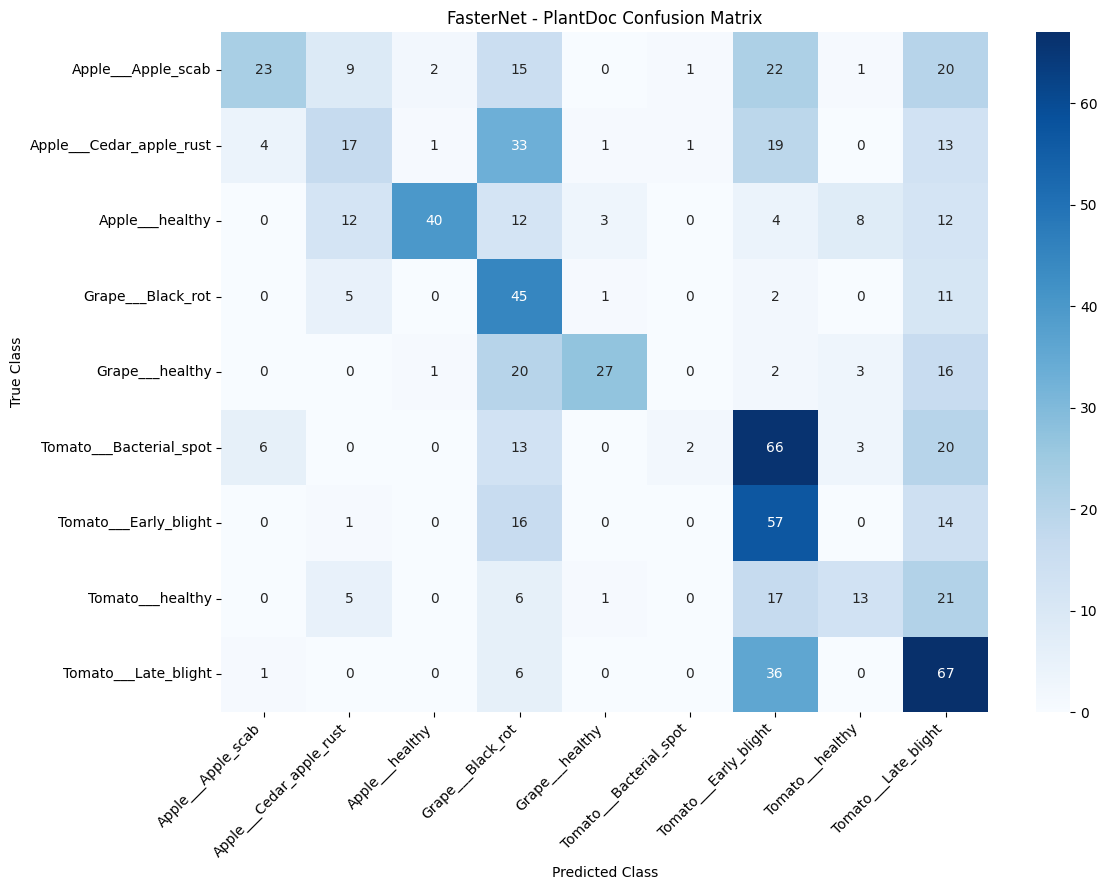

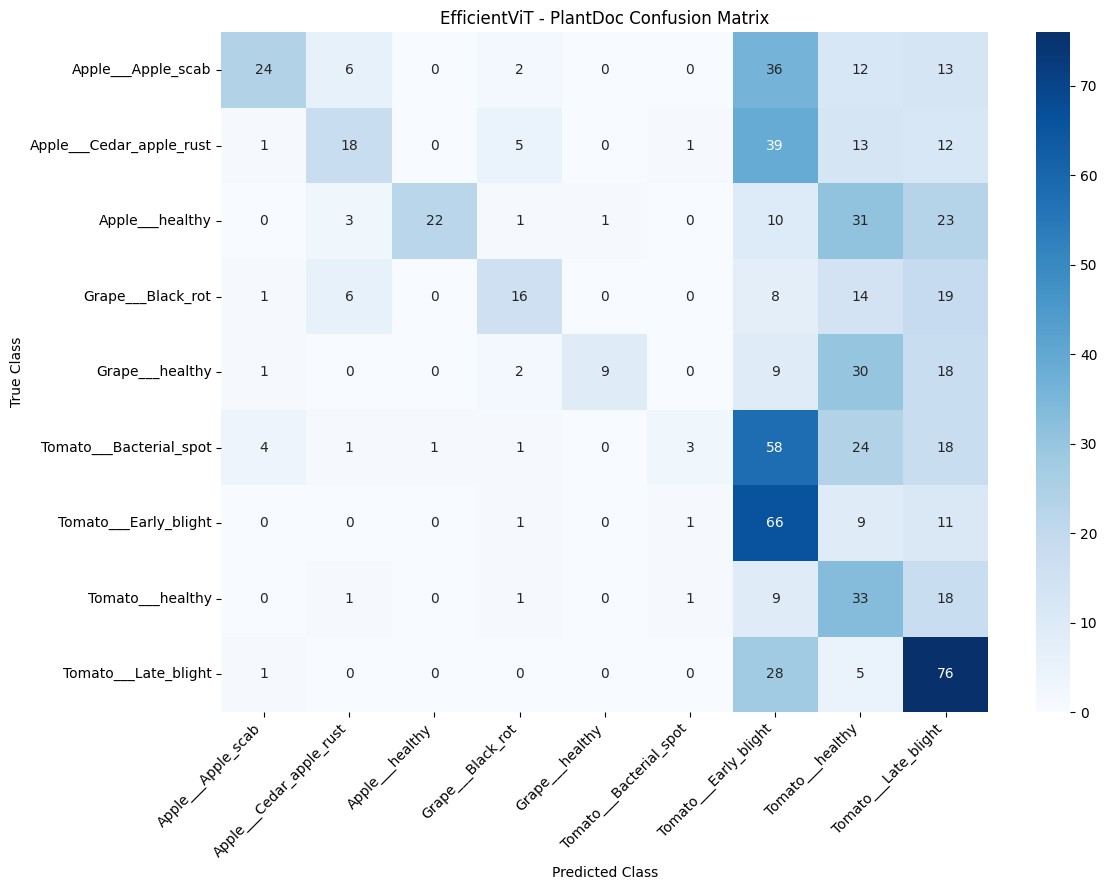

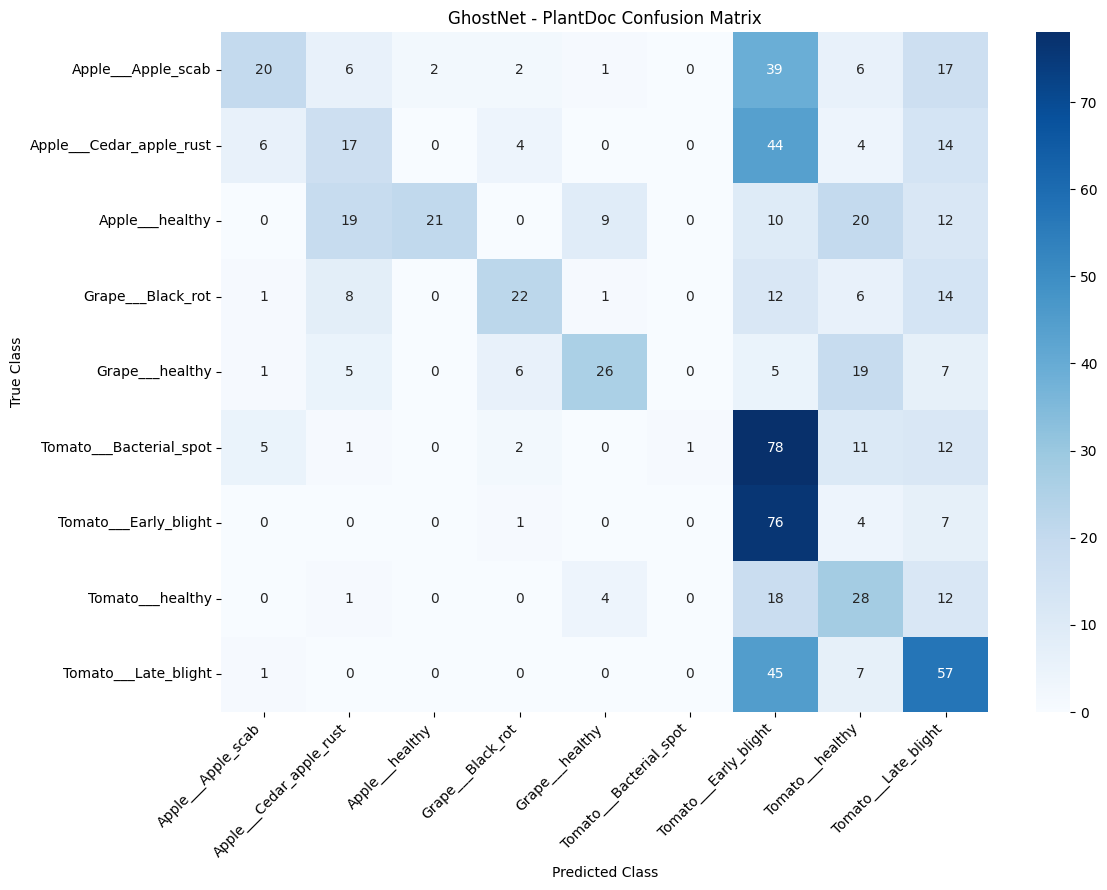


Per-Class Recall Comparison (%):


Model,EfficientViT,FasterNet,GhostNet
Class,,,
Apple___Apple_scab,25.81,24.73,21.51
Apple___Cedar_apple_rust,20.22,19.10,19.10
Apple___healthy,24.18,43.96,23.08
Grape___Black_rot,25.00,70.31,34.38
Grape___healthy,13.04,39.13,37.68
Tomato___Bacterial_spot,2.73,1.82,0.91
Tomato___Early_blight,75.00,64.77,86.36
Tomato___Late_blight,69.09,60.91,51.82
Tomato___healthy,52.38,20.63,44.44


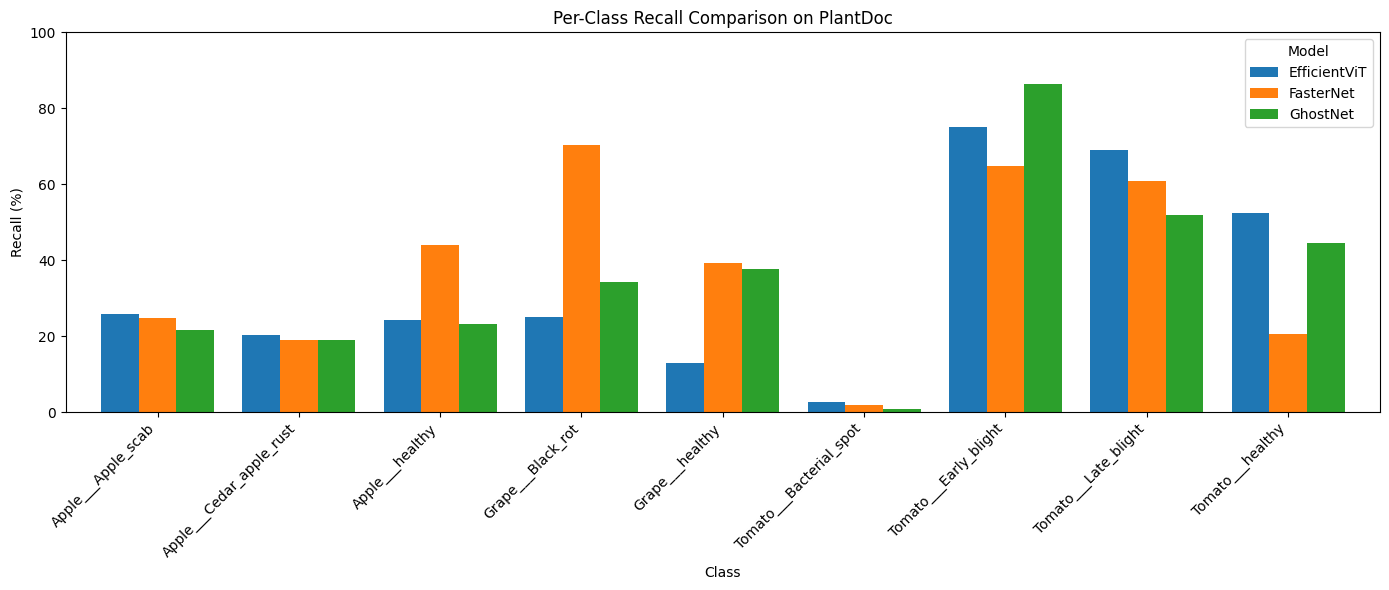


Diseased Images Incorrectly Predicted as Healthy:


,Model,Crop,Disease Images,Predicted as Healthy
0,FasterNet,Apple,182,3
1,FasterNet,Grape,64,1
2,FasterNet,Tomato,308,3
3,EfficientViT,Apple,182,0
4,EfficientViT,Grape,64,0
5,EfficientViT,Tomato,308,38
6,GhostNet,Apple,182,2
7,GhostNet,Grape,64,1
8,GhostNet,Tomato,308,22


In [16]:

# 7. Confusion Matrices & Per-Class Recall Analysis

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score

# Create directory for visualizations
FIGURES_DIR = CLASSIFICATION_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

class_names = [
    idx_to_class[i] for i in range(len(class_to_idx))
]

recall_results = []
false_healthy_results = []

for model_name in models.keys():

    predictions_df = all_predictions[model_name]
    cm = all_confusion_matrices[model_name]

    # 1. Plot confusion matrix
    fig, ax = plt.subplots(figsize=(12, 9))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f"{model_name} - PlantDoc Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"{model_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # 2. Calculate per-class recall
    per_class_recall = recall_score(
        predictions_df["label"],
        predictions_df["predicted_label"],
        labels=list(range(len(class_names))),
        average=None,
        zero_division=0
    )

    for class_idx, recall_value in enumerate(per_class_recall):
        recall_results.append({
            "Model": model_name,
            "Class": class_names[class_idx],
            "Recall": recall_value,
            "Recall (%)": recall_value * 100
        })

    # 3. Count diseased images predicted as healthy
    for crop in ["Apple", "Grape", "Tomato"]:

        healthy_class = f"{crop}___healthy"

        crop_diseases = predictions_df[
            (predictions_df["class_name"].str.startswith(f"{crop}___")) &
            (predictions_df["class_name"] != healthy_class)
        ]

        false_healthy = (
            crop_diseases["predicted_class"] == healthy_class
        ).sum()

        false_healthy_results.append({
            "Model": model_name,
            "Crop": crop,
            "Disease Images": len(crop_diseases),
            "Predicted as Healthy": int(false_healthy)
        })

# 4. Save and display per-class recall
recall_df = pd.DataFrame(recall_results)

recall_df.to_csv(
    CLASSIFICATION_DIR / "per_class_recall.csv",
    index=False
)

recall_pivot = recall_df.pivot(
    index="Class",
    columns="Model",
    values="Recall (%)"
)

print("\nPer-Class Recall Comparison (%):")
display(recall_pivot.round(2))

# 5. Plot per-class recall comparison
ax = recall_pivot.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

ax.set_title("Per-Class Recall Comparison on PlantDoc")
ax.set_xlabel("Class")
ax.set_ylabel("Recall (%)")
ax.set_ylim(0, 100)
ax.legend(title="Model")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "per_class_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 6. Save and display false-healthy predictions
false_healthy_df = pd.DataFrame(false_healthy_results)

false_healthy_df.to_csv(
    CLASSIFICATION_DIR / "diseased_predicted_as_healthy.csv",
    index=False
)

print("\nDiseased Images Incorrectly Predicted as Healthy:")
display(false_healthy_df)


In [17]:

# 8.1. Inspect Model Layers for Grad-CAM

import torch.nn as nn

for model_name, model in models.items():

    print(f"\n{'=' * 60}")
    print(f"{model_name} - Candidate Grad-CAM Layers")
    print(f"{'=' * 60}")

    candidates = []

    for layer_name, layer in model.named_modules():

        if isinstance(layer, nn.Conv2d):
            candidates.append((
                layer_name,
                layer.in_channels,
                layer.out_channels,
                layer.kernel_size
            ))

    print(f"Total Conv2d layers: {len(candidates)}")
    print("\nLast 12 convolutional layers:\n")

    for name, in_channels, out_channels, kernel_size in candidates[-12:]:
        print(
            f"{name} | "
            f"in={in_channels}, "
            f"out={out_channels}, "
            f"kernel={kernel_size}"
        )



FasterNet - Candidate Grad-CAM Layers
Total Conv2d layers: 44

Last 12 convolutional layers:

stages.2.blocks.7.mlp.0 | in=160, out=320, kernel=(1, 1)
stages.2.blocks.7.mlp.3 | in=320, out=160, kernel=(1, 1)
stages.2.blocks.7.spatial_mixing.partial_conv3 | in=40, out=40, kernel=(3, 3)
stages.2.downsample.reduction | in=80, out=160, kernel=(2, 2)
stages.3.blocks.0.mlp.0 | in=320, out=640, kernel=(1, 1)
stages.3.blocks.0.mlp.3 | in=640, out=320, kernel=(1, 1)
stages.3.blocks.0.spatial_mixing.partial_conv3 | in=80, out=80, kernel=(3, 3)
stages.3.blocks.1.mlp.0 | in=320, out=640, kernel=(1, 1)
stages.3.blocks.1.mlp.3 | in=640, out=320, kernel=(1, 1)
stages.3.blocks.1.spatial_mixing.partial_conv3 | in=80, out=80, kernel=(3, 3)
stages.3.downsample.reduction | in=160, out=320, kernel=(2, 2)
conv_head | in=320, out=1280, kernel=(1, 1)

EfficientViT - Candidate Grad-CAM Layers
Total Conv2d layers: 50

Last 12 convolutional layers:

stages.3.blocks.1.context_module.main.proj.conv | in=256, out=

In [18]:

# 8.2. Validate Grad-CAM Target Layers

TARGET_LAYERS = {
    "FasterNet": "stages.3.blocks.1",
    "EfficientViT": "stages.3.blocks.2",
    "GhostNet": "blocks.9.0"
}

def get_module_by_name(model, layer_name):
    return model.get_submodule(layer_name)

sample_images, _, _ = next(iter(test_loader))
sample_input = sample_images[:1].to(device)

for model_name, model in models.items():

    model.eval()
    layer = get_module_by_name(
        model, TARGET_LAYERS[model_name]
    )

    captured = {}

    def forward_hook(module, inputs, output):
        captured["activation"] = output

    handle = layer.register_forward_hook(forward_hook)

    try:
        with torch.enable_grad():
            model.zero_grad(set_to_none=True)

            output = model(sample_input)
            target_score = output.max(dim=1).values.sum()

            activation = captured["activation"]
            gradient = torch.autograd.grad(
                target_score,
                activation,
                retain_graph=False
            )[0]

        print(f"\n{model_name}")
        print("Target layer:", TARGET_LAYERS[model_name])
        print("Activation shape:", tuple(activation.shape))
        print("Gradient shape:", tuple(gradient.shape))
        print("Gradient finite:", bool(torch.isfinite(gradient).all()))
        print("Gradient nonzero:", bool((gradient.abs() > 0).any()))

        assert activation.ndim == 4, "Expected 4D feature maps"
        assert gradient.shape == activation.shape
        assert torch.isfinite(gradient).all()
        assert (gradient.abs() > 0).any()

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)

print("\nTarget layer validation completed!")



FasterNet
Target layer: stages.3.blocks.1
Activation shape: (1, 320, 7, 7)
Gradient shape: (1, 320, 7, 7)
Gradient finite: True
Gradient nonzero: True

EfficientViT
Target layer: stages.3.blocks.2
Activation shape: (1, 128, 7, 7)
Gradient shape: (1, 128, 7, 7)
Gradient finite: True
Gradient nonzero: True

GhostNet
Target layer: blocks.9.0
Activation shape: (1, 960, 7, 7)
Gradient shape: (1, 960, 7, 7)
Gradient finite: True
Gradient nonzero: True

Target layer validation completed!


In [19]:

# 8.3. Select Representative Samples for Grad-CAM

import numpy as np
import pandas as pd

GRADCAM_DIR = RESULTS_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)

# Combine test labels with predictions from all models
selection_df = test_df.reset_index(drop=True).copy()
selection_df["sample_index"] = np.arange(len(selection_df))

correct_columns = []

for model_name in models.keys():
    predictions_df = all_predictions[model_name].reset_index(drop=True)

    selection_df[f"{model_name}_prediction"] = (
        predictions_df["predicted_class"].to_numpy()
    )

    correct_col = f"{model_name}_correct"

    selection_df[correct_col] = (
        predictions_df["correct"].to_numpy().astype(bool)
    )

    correct_columns.append(correct_col)

# Count how many models classified each image correctly
selection_df["correct_count"] = (
    selection_df[correct_columns].sum(axis=1)
)

selected_indices = []

# Select two images from each of the nine classes
for class_idx in range(len(class_to_idx)):

    class_samples = selection_df[
        selection_df["label"] == class_idx
    ].copy()

    assert len(class_samples) >= 2, (
        f"Not enough images for class {class_idx}"
    )

    # Reproducible tie-breaking
    class_samples["random_order"] = rng.random(
        len(class_samples)
    )

    # Image classified correctly by the most models
    higher = class_samples.sort_values(
        ["correct_count", "random_order"],
        ascending=[False, True]
    ).iloc[0]

    # Different image classified correctly by the fewest models
    remaining = class_samples[
        class_samples["sample_index"] != higher["sample_index"]
    ]

    lower = remaining.sort_values(
        ["correct_count", "random_order"],
        ascending=[True, True]
    ).iloc[0]

    selected_indices.extend([
        int(higher["sample_index"]),
        int(lower["sample_index"])
    ])

# Save the selected samples
gradcam_samples = selection_df.iloc[selected_indices].copy()

gradcam_samples["Selection"] = [
    "Higher correctness" if i % 2 == 0
    else "Lower correctness"
    for i in range(len(gradcam_samples))
]

gradcam_samples.to_csv(
    GRADCAM_DIR / "selected_samples.csv",
    index=False
)

print("Total selected images:", len(gradcam_samples))
print("Number of classes:", gradcam_samples["class_name"].nunique())

print("\nSelected Samples:")
display(
    gradcam_samples[
        [
            "sample_index",
            "class_name",
            "Selection",
            "correct_count",
            "FasterNet_correct",
            "EfficientViT_correct",
            "GhostNet_correct"
        ]
    ]
)

print("\nCorrect and incorrect samples per model:")

for model_name in models.keys():
    n_correct = int(
        gradcam_samples[f"{model_name}_correct"].sum()
    )

    print(
        f"{model_name}: "
        f"{n_correct} correct, "
        f"{len(gradcam_samples) - n_correct} incorrect"
    )


Total selected images: 18
Number of classes: 9

Selected Samples:


,sample_index,class_name,Selection,correct_count,FasterNet_correct,EfficientViT_correct,GhostNet_correct
85,85,Apple___Apple_scab,Higher correctness,3,True,True,True
27,27,Apple___Apple_scab,Lower correctness,0,False,False,False
94,94,Apple___Cedar_apple_rust,Higher correctness,3,True,True,True
135,135,Apple___Cedar_apple_rust,Lower correctness,0,False,False,False
268,268,Apple___healthy,Higher correctness,3,True,True,True
204,204,Apple___healthy,Lower correctness,0,False,False,False
280,280,Grape___Black_rot,Higher correctness,3,True,True,True
291,291,Grape___Black_rot,Lower correctness,0,False,False,False
374,374,Grape___healthy,Higher correctness,3,True,True,True
394,394,Grape___healthy,Lower correctness,0,False,False,False



Correct and incorrect samples per model:
FasterNet: 9 correct, 9 incorrect
EfficientViT: 9 correct, 9 incorrect
GhostNet: 8 correct, 10 incorrect



Generating Grad-CAM for FasterNet...
FasterNet: completed.

Generating Grad-CAM for EfficientViT...
EfficientViT: completed.

Generating Grad-CAM for GhostNet...
GhostNet: completed.

All Grad-CAM visualizations saved!
Location: /content/drive/MyDrive/C3_Results/gradcam


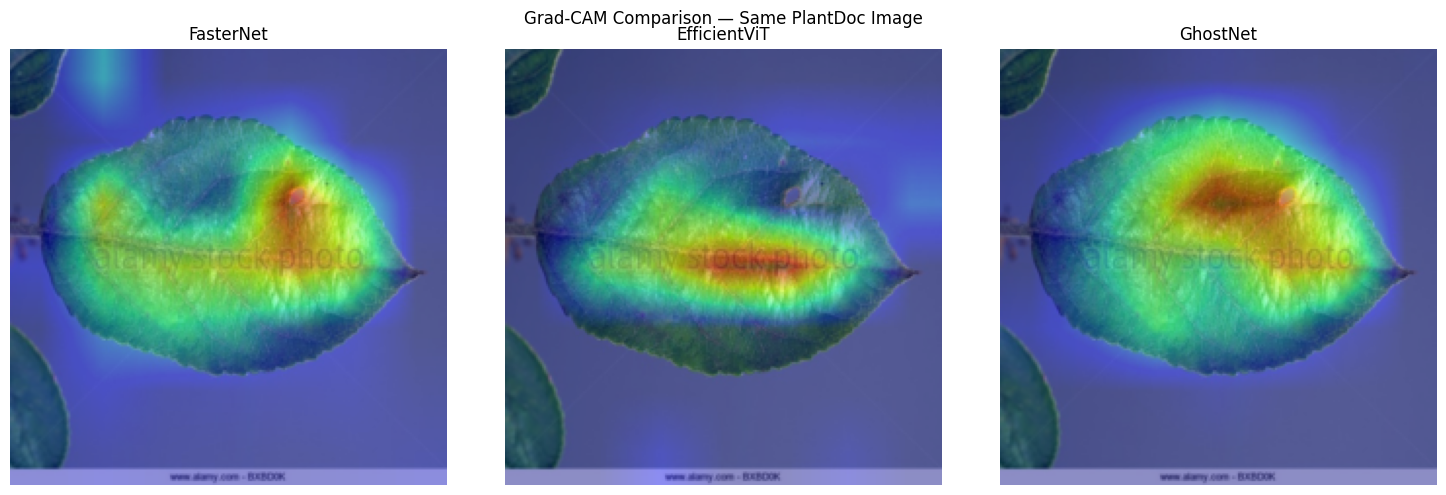

In [20]:

# 8.4. Generate and Save Grad-CAM Heatmaps

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

HEATMAP_DIR = GRADCAM_DIR / "heatmaps"
FIGURE_DIR = GRADCAM_DIR / "figures"

HEATMAP_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def compute_gradcam(model, image_tensor, target_layer):
    captured = {}

    def hook_fn(module, inputs, output):
        captured["activation"] = output

    handle = target_layer.register_forward_hook(hook_fn)

    try:
        model.eval()
        model.zero_grad(set_to_none=True)

        with torch.enable_grad():
            logits = model(image_tensor)
            predicted_class = int(logits.argmax(dim=1).item())

            activation = captured["activation"]
            score = logits[0, predicted_class]

            gradients = torch.autograd.grad(
                score, activation
            )[0]

            weights = gradients.mean(dim=(2, 3), keepdim=True)

            cam = F.relu(
                (weights * activation).sum(dim=1, keepdim=True)
            )

            cam = F.interpolate(
                cam,
                size=image_tensor.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            cam = cam[0, 0].detach().cpu().numpy()
            cam -= cam.min()
            cam /= (cam.max() + 1e-8)

        return cam, predicted_class

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)


def to_display_image(image_tensor):
    image = image_tensor.squeeze(0).detach().cpu().numpy()
    image = image.transpose(1, 2, 0)
    return np.clip(image * std + mean, 0, 1)


for model_name, model in models.items():

    target_layer = model.get_submodule(
        TARGET_LAYERS[model_name]
    )

    print(f"\nGenerating Grad-CAM for {model_name}...")

    for row in gradcam_samples.itertuples():

        sample_index = int(row.sample_index)

        heatmap_path = (
            HEATMAP_DIR / f"{model_name}_{sample_index}.npy"
        )
        figure_path = (
            FIGURE_DIR / f"{model_name}_{sample_index}.png"
        )

        # Skip already completed samples
        if heatmap_path.exists() and figure_path.exists():
            continue

        image_tensor, true_label, _ = test_dataset[sample_index]
        image_input = image_tensor.unsqueeze(0).to(device)

        cam, predicted_label = compute_gradcam(
            model, image_input, target_layer
        )

        # Save numeric heatmap
        np.save(heatmap_path, cam.astype(np.float32))

        image = to_display_image(image_input)

        fig, axes = plt.subplots(1, 3, figsize=(12, 4))

        axes[0].imshow(image)
        axes[0].set_title("Original")

        axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
        axes[1].set_title("Grad-CAM")

        axes[2].imshow(image)
        axes[2].imshow(
            cam, cmap="jet", alpha=0.45,
            vmin=0, vmax=1
        )
        axes[2].set_title("Overlay")

        for ax in axes:
            ax.axis("off")

        status = (
            "Correct" if predicted_label == true_label
            else "Incorrect"
        )

        fig.suptitle(
            f"{model_name} | {status}\n"
            f"True: {idx_to_class[true_label]}\n"
            f"Predicted: {idx_to_class[predicted_label]}",
            fontsize=10
        )

        plt.tight_layout()
        plt.savefig(
            figure_path, dpi=200, bbox_inches="tight"
        )
        plt.close(fig)

    print(f"{model_name}: completed.")

print("\nAll Grad-CAM visualizations saved!")
print("Location:", GRADCAM_DIR)

# Display one example from each model
sample_index = int(gradcam_samples.iloc[0]["sample_index"])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, model_name in zip(axes, models.keys()):

    image_tensor, _, _ = test_dataset[sample_index]
    image = to_display_image(image_tensor.unsqueeze(0))

    cam = np.load(
        HEATMAP_DIR / f"{model_name}_{sample_index}.npy"
    )

    ax.imshow(image)
    ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(model_name)
    ax.axis("off")

plt.suptitle("Grad-CAM Comparison — Same PlantDoc Image")
plt.tight_layout()
plt.show()


In [21]:

# 9.1. Select Samples for Insertion & Deletion Evaluation

import numpy as np
import pandas as pd

INSERTION_DELETION_DIR = RESULTS_DIR / "insertion_deletion"
INSERTION_DELETION_DIR.mkdir(parents=True, exist_ok=True)

SAMPLES_PER_CLASS = 10
RANDOM_SEED = 42

# Reuse saved sample selection if it already exists
samples_path = INSERTION_DELETION_DIR / "evaluation_samples.csv"

if samples_path.exists():
    evaluation_samples = pd.read_csv(samples_path)
    print("Loaded previously selected evaluation samples.")

else:
    rng = np.random.default_rng(RANDOM_SEED)
    selected_indices = []

    for class_idx in range(len(class_to_idx)):

        class_indices = np.flatnonzero(
            test_df["label"].to_numpy() == class_idx
        )

        assert len(class_indices) >= SAMPLES_PER_CLASS, (
            f"Not enough images for class {class_idx}"
        )

        chosen = rng.choice(
            class_indices,
            size=SAMPLES_PER_CLASS,
            replace=False
        )

        selected_indices.extend(chosen.tolist())

    evaluation_samples = test_df.iloc[selected_indices].copy()

    evaluation_samples.insert(
        0, "sample_index", selected_indices
    )

    evaluation_samples.to_csv(
        samples_path,
        index=False
    )

    print("New evaluation samples selected and saved.")

# Validate selection
assert len(evaluation_samples) == 90
assert evaluation_samples["sample_index"].nunique() == 90
assert evaluation_samples["class_name"].nunique() == 9

print("\nTotal evaluation images:", len(evaluation_samples))
print("Number of classes:", evaluation_samples["class_name"].nunique())

print("\nImages per class:")
display(
    evaluation_samples["class_name"]
    .value_counts()
    .sort_index()
)

print("\nSample preview:")
display(
    evaluation_samples[
        ["sample_index", "class_name", "label"]
    ].head(10)
)

print("\nSaved to:", samples_path)


New evaluation samples selected and saved.

Total evaluation images: 90
Number of classes: 9

Images per class:


,count
class_name,
Apple___Apple_scab,10
Apple___Cedar_apple_rust,10
Apple___healthy,10
Grape___Black_rot,10
Grape___healthy,10
Tomato___Bacterial_spot,10
Tomato___Early_blight,10
Tomato___Late_blight,10
Tomato___healthy,10



Sample preview:


,sample_index,class_name,label
89,89,Apple___Apple_scab,0
65,65,Apple___Apple_scab,0
7,7,Apple___Apple_scab,0
56,56,Apple___Apple_scab,0
38,38,Apple___Apple_scab,0
87,87,Apple___Apple_scab,0
63,63,Apple___Apple_scab,0
8,8,Apple___Apple_scab,0
18,18,Apple___Apple_scab,0
76,76,Apple___Apple_scab,0



Saved to: /content/drive/MyDrive/C3_Results/insertion_deletion/evaluation_samples.csv


In [22]:

# 9.2. Define Insertion & Deletion Evaluation Functions

import numpy as np
import torch
import torch.nn.functional as F

# Evaluation settings
NUM_STEPS = 20
EVAL_BATCH_SIZE = 8

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32,
    device=device
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32,
    device=device
).view(1, 3, 1, 1)


def insertion_deletion_auc(
    model,
    image_tensor,
    heatmap,
    target_class,
    num_steps=NUM_STEPS,
    batch_size=EVAL_BATCH_SIZE
):
    """
    Calculate Insertion and Deletion AUC for one image.

    Uses a black baseline in RGB pixel space.
    Target class stays fixed to the original predicted class.
    """

    model.eval()

    # Input shape: [1, 3, H, W]
    image_tensor = image_tensor.to(device)

    # Convert normalized image to RGB pixel space
    original = (
        image_tensor * IMAGENET_STD + IMAGENET_MEAN
    ).clamp(0, 1)

    # Black baseline (RGB = 0)
    baseline = torch.zeros_like(original)

    # Flatten and rank pixels by Grad-CAM importance
    h, w = original.shape[-2:]

    heatmap_tensor = torch.as_tensor(
        heatmap,
        dtype=torch.float32,
        device=device
    )

    assert tuple(heatmap_tensor.shape) == (h, w)
    assert torch.isfinite(heatmap_tensor).all()

    ranked_indices = torch.argsort(
        heatmap_tensor.flatten(),
        descending=True,
        stable=True
    )

    # Evaluation fractions from 0% to 100%
    fractions = np.linspace(0, 1, num_steps + 1)

    insertion_images = []
    deletion_images = []

    original_flat = original.reshape(1, 3, -1)
    baseline_flat = baseline.reshape(1, 3, -1)

    for fraction in fractions:

        n_pixels = int(round(fraction * h * w))

        mask = torch.zeros(
            h * w,
            dtype=torch.bool,
            device=device
        )

        mask[ranked_indices[:n_pixels]] = True
        mask = mask.view(1, 1, -1)

        # Insertion: baseline -> original
        inserted = torch.where(
            mask, original_flat, baseline_flat
        ).reshape(1, 3, h, w)

        # Deletion: original -> baseline
        deleted = torch.where(
            mask, baseline_flat, original_flat
        ).reshape(1, 3, h, w)

        insertion_images.append(inserted)
        deletion_images.append(deleted)

    # Combine and normalize perturbed images
    all_images = torch.cat(
        insertion_images + deletion_images,
        dim=0
    )

    all_images = (
        all_images - IMAGENET_MEAN
    ) / IMAGENET_STD

    # Predict in small batches
    scores = []

    with torch.inference_mode():
        for batch in all_images.split(batch_size):

            logits = model(batch)
            probabilities = torch.softmax(logits, dim=1)

            scores.extend(
                probabilities[:, target_class]
                .cpu()
                .numpy()
                .tolist()
            )

    n_points = len(fractions)

    insertion_scores = np.array(
        scores[:n_points], dtype=np.float64
    )

    deletion_scores = np.array(
        scores[n_points:], dtype=np.float64
    )

    # Normalized area under the curves
    insertion_auc = float(
        np.trapezoid(insertion_scores, fractions)
    )

    deletion_auc = float(
        np.trapezoid(deletion_scores, fractions)
    )

    return {
        "fractions": fractions,
        "insertion_scores": insertion_scores,
        "deletion_scores": deletion_scores,
        "insertion_auc": insertion_auc,
        "deletion_auc": deletion_auc
    }


print("Insertion & Deletion functions defined successfully!")
print("Evaluation steps:", NUM_STEPS)
print("Evaluation batch size:", EVAL_BATCH_SIZE)
print("Baseline: Black image (RGB = 0)")
print("Target class: Original predicted class")


Insertion & Deletion functions defined successfully!
Evaluation steps: 20
Evaluation batch size: 8
Baseline: Black image (RGB = 0)
Target class: Original predicted class


Model: FasterNet
True class: Apple___Apple_scab
Predicted class: Tomato___Early_blight
Insertion AUC: 0.3252
Deletion AUC: 0.0336


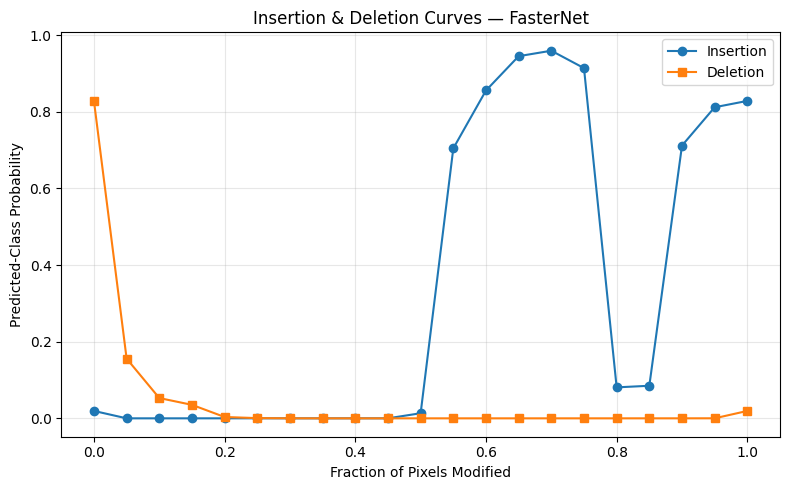

In [23]:

# 9.3. Test Insertion & Deletion on One Image

import matplotlib.pyplot as plt

# Select one image from the evaluation sample
sample_index = int(evaluation_samples.iloc[0]["sample_index"])

# Load image
image_tensor, true_label, _ = test_dataset[sample_index]
image_input = image_tensor.unsqueeze(0).to(device)

# Select model and target layer
model_name = "FasterNet"
model = models[model_name]

target_layer = model.get_submodule(
    TARGET_LAYERS[model_name]
)

# Generate Grad-CAM for this image
heatmap, predicted_class = compute_gradcam(
    model,
    image_input,
    target_layer
)

# Calculate Insertion and Deletion AUC
result = insertion_deletion_auc(
    model=model,
    image_tensor=image_input,
    heatmap=heatmap,
    target_class=predicted_class
)

print("Model:", model_name)
print("True class:", idx_to_class[true_label])
print("Predicted class:", idx_to_class[predicted_class])
print(f"Insertion AUC: {result['insertion_auc']:.4f}")
print(f"Deletion AUC: {result['deletion_auc']:.4f}")

# Plot both curves
plt.figure(figsize=(8, 5))

plt.plot(
    result["fractions"],
    result["insertion_scores"],
    marker="o",
    label="Insertion"
)

plt.plot(
    result["fractions"],
    result["deletion_scores"],
    marker="s",
    label="Deletion"
)

plt.xlabel("Fraction of Pixels Modified")
plt.ylabel("Predicted-Class Probability")
plt.title(f"Insertion & Deletion Curves — {model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

# 9.4. Full Insertion & Deletion Evaluation

import numpy as np
import pandas as pd
import torch
import time

# Output directories
CURVES_DIR = INSERTION_DELETION_DIR / "curves"
CURVES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_CSV = INSERTION_DELETION_DIR / "insertion_deletion_results.csv"

# Load existing results to support resuming
if RESULTS_CSV.exists():
    results_df = pd.read_csv(RESULTS_CSV)
    print(f"Loaded {len(results_df)} existing results.")
else:
    results_df = pd.DataFrame()

# Track completed model-image pairs
if not results_df.empty:
    completed = set(
        zip(
            results_df["Model"],
            results_df["sample_index"].astype(int)
        )
    )
else:
    completed = set()

total_evaluations = len(evaluation_samples) * len(models)
start_time = time.time()

print(f"Total planned evaluations: {total_evaluations}")
print(f"Already completed: {len(completed)}")

for model_name, model in models.items():

    model.eval()

    target_layer = model.get_submodule(
        TARGET_LAYERS[model_name]
    )

    print(f"\nEvaluating {model_name}...")

    for row in evaluation_samples.itertuples(index=False):

        sample_index = int(row.sample_index)
        key = (model_name, sample_index)

        if key in completed:
            continue

        # Load test image
        image_tensor, true_label, _ = test_dataset[sample_index]
        image_input = image_tensor.unsqueeze(0).to(device)

        # Generate Grad-CAM for the predicted class
        heatmap, predicted_class = compute_gradcam(
            model,
            image_input,
            target_layer
        )

        # Calculate insertion and deletion curves/AUC
        result = insertion_deletion_auc(
            model=model,
            image_tensor=image_input,
            heatmap=heatmap,
            target_class=predicted_class
        )

        # Save individual curves
        curve_path = (
            CURVES_DIR / f"{model_name}_{sample_index}.npz"
        )

        np.savez_compressed(
            curve_path,
            fractions=result["fractions"],
            insertion_scores=result["insertion_scores"],
            deletion_scores=result["deletion_scores"]
        )

        # Append metrics
        new_row = pd.DataFrame([{
            "Model": model_name,
            "sample_index": sample_index,
            "True Class": idx_to_class[true_label],
            "Predicted Class": idx_to_class[predicted_class],
            "Correct": bool(predicted_class == true_label),
            "Insertion AUC": result["insertion_auc"],
            "Deletion AUC": result["deletion_auc"]
        }])

        results_df = pd.concat(
            [results_df, new_row],
            ignore_index=True
        )

        # Save after every image
        results_df.to_csv(RESULTS_CSV, index=False)
        completed.add(key)

        # Progress update every 10 evaluations
        if len(completed) % 10 == 0:
            elapsed = (time.time() - start_time) / 60

            print(
                f"Completed {len(completed)}/{total_evaluations} "
                f"| Elapsed: {elapsed:.1f} min",
                flush=True
            )

    print(f"{model_name}: completed.")

print("\nFull Insertion & Deletion Evaluation Completed!")
print("Total results:", len(results_df))
print("Results saved to:", RESULTS_CSV)

# Display summary
summary_df = (
    results_df.groupby("Model")[
        ["Insertion AUC", "Deletion AUC"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nInsertion & Deletion Summary:")
display(summary_df)


Total planned evaluations: 270
Already completed: 0

Evaluating FasterNet...
Completed 10/270 | Elapsed: 0.0 min
Completed 20/270 | Elapsed: 0.1 min
Completed 30/270 | Elapsed: 0.1 min
Completed 40/270 | Elapsed: 0.1 min
Completed 50/270 | Elapsed: 0.2 min
Completed 60/270 | Elapsed: 0.2 min
Completed 70/270 | Elapsed: 0.2 min
Completed 80/270 | Elapsed: 0.2 min
Completed 90/270 | Elapsed: 0.2 min
FasterNet: completed.

Evaluating EfficientViT...
Completed 100/270 | Elapsed: 0.2 min
Completed 110/270 | Elapsed: 0.2 min
Completed 120/270 | Elapsed: 0.3 min
Completed 130/270 | Elapsed: 0.3 min
Completed 140/270 | Elapsed: 0.3 min
Completed 150/270 | Elapsed: 0.3 min
Completed 160/270 | Elapsed: 0.4 min
Completed 170/270 | Elapsed: 0.4 min
Completed 180/270 | Elapsed: 0.4 min
EfficientViT: completed.

Evaluating GhostNet...
Completed 190/270 | Elapsed: 0.4 min
Completed 200/270 | Elapsed: 0.4 min
Completed 210/270 | Elapsed: 0.5 min
Completed 220/270 | Elapsed: 0.5 min
Completed 230/270 |

Insertion AUC         Deletion AUC        
                      mean     std         mean     std
Model                                                  
EfficientViT        0.5808  0.2891       0.3436  0.2755
FasterNet           0.6117  0.2801       0.2542  0.2639
GhostNet            0.6527  0.2666       0.2881  0.2396

Final AUC Summary:


,Model,Samples,Insertion_Mean,Insertion_STD,Deletion_Mean,Deletion_STD
0,EfficientViT,90,0.5808,0.2891,0.3436,0.2755
1,FasterNet,90,0.6117,0.2801,0.2542,0.2639
2,GhostNet,90,0.6527,0.2666,0.2881,0.2396


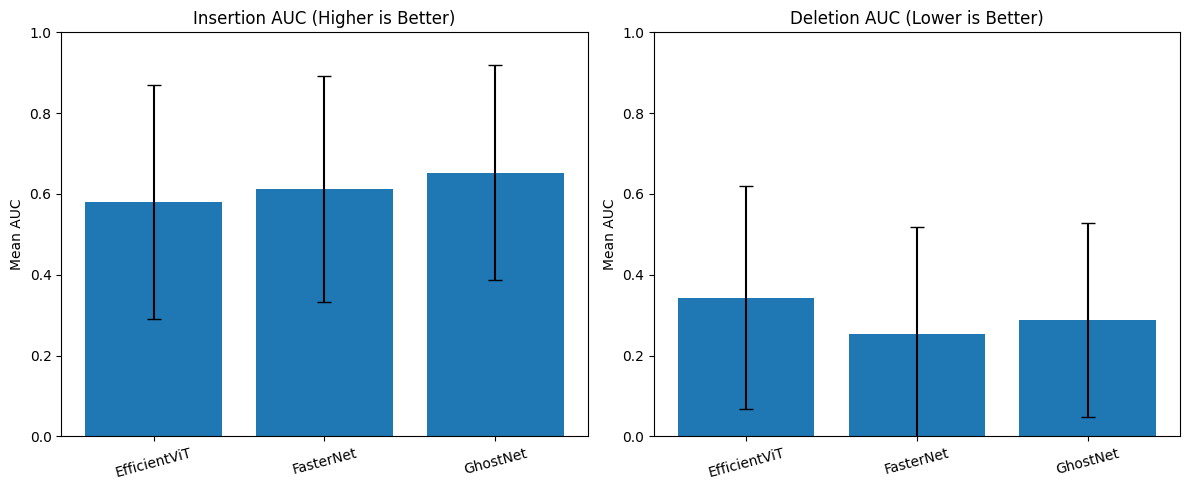

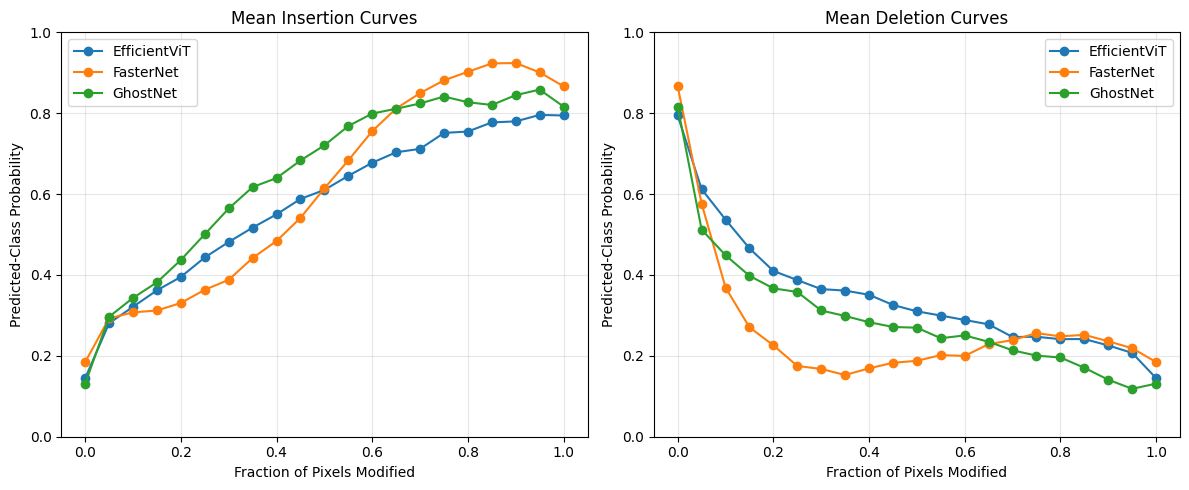


Final figures and AUC summary saved successfully!
Location: /content/drive/MyDrive/C3_Results/insertion_deletion


In [25]:

# 9.5. Final Insertion & Deletion AUC Comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FIGURES_DIR = INSERTION_DELETION_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load saved evaluation results
results_df = pd.read_csv(
    INSERTION_DELETION_DIR / "insertion_deletion_results.csv"
)

# Verify all evaluations are complete
assert len(results_df) == 270, "Incomplete evaluation results"
assert not results_df.duplicated(
    subset=["Model", "sample_index"]
).any(), "Duplicate evaluations found"

# Calculate summary statistics
auc_summary = (
    results_df.groupby("Model")
    .agg(
        Samples=("sample_index", "count"),
        Insertion_Mean=("Insertion AUC", "mean"),
        Insertion_STD=("Insertion AUC", "std"),
        Deletion_Mean=("Deletion AUC", "mean"),
        Deletion_STD=("Deletion AUC", "std")
    )
    .reset_index()
)

auc_summary.to_csv(
    INSERTION_DELETION_DIR / "auc_summary.csv",
    index=False
)

print("Final AUC Summary:")
display(auc_summary.round(4))

# Plot mean AUC with standard deviation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

model_names = auc_summary["Model"].tolist()
x = np.arange(len(model_names))

axes[0].bar(
    x,
    auc_summary["Insertion_Mean"],
    yerr=auc_summary["Insertion_STD"],
    capsize=5
)

axes[0].set_title("Insertion AUC (Higher is Better)")
axes[0].set_ylabel("Mean AUC")
axes[0].set_ylim(0, 1)
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=15)

axes[1].bar(
    x,
    auc_summary["Deletion_Mean"],
    yerr=auc_summary["Deletion_STD"],
    capsize=5
)

axes[1].set_title("Deletion AUC (Lower is Better)")
axes[1].set_ylabel("Mean AUC")
axes[1].set_ylim(0, 1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_names, rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Calculate average insertion/deletion curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for model_name in model_names:

    model_rows = results_df[
        results_df["Model"] == model_name
    ]

    insertion_curves = []
    deletion_curves = []

    for sample_index in model_rows["sample_index"]:

        curve_path = (
            CURVES_DIR / f"{model_name}_{int(sample_index)}.npz"
        )

        with np.load(curve_path) as curve:
            fractions = curve["fractions"]
            insertion_curves.append(curve["insertion_scores"])
            deletion_curves.append(curve["deletion_scores"])

    mean_insertion = np.mean(insertion_curves, axis=0)
    mean_deletion = np.mean(deletion_curves, axis=0)

    axes[0].plot(
        fractions,
        mean_insertion,
        marker="o",
        label=model_name
    )

    axes[1].plot(
        fractions,
        mean_deletion,
        marker="o",
        label=model_name
    )

axes[0].set_title("Mean Insertion Curves")
axes[1].set_title("Mean Deletion Curves")

for ax in axes:
    ax.set_xlabel("Fraction of Pixels Modified")
    ax.set_ylabel("Predicted-Class Probability")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "mean_insertion_deletion_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFinal figures and AUC summary saved successfully!")
print("Location:", INSERTION_DELETION_DIR)


In [26]:

# 10. Final Results Verification & Export

import pandas as pd
import numpy as np

FINAL_DIR = RESULTS_DIR / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load saved classification metrics
classification_df = pd.read_csv(
    CLASSIFICATION_DIR / "model_comparison.csv"
)

# 2. Load saved Insertion & Deletion metrics
auc_df = pd.read_csv(
    INSERTION_DELETION_DIR / "auc_summary.csv"
)

# 3. Merge both evaluations
final_df = classification_df.merge(
    auc_df,
    on="Model",
    how="inner",
    validate="one_to_one"
)

# 4. Verify all three models
expected_models = set(models.keys())

assert set(final_df["Model"]) == expected_models, (
    "Missing or unexpected models in final comparison"
)

# 5. Verify evaluation counts
assert len(test_dataset) == 777
assert len(gradcam_samples) == 18
assert len(evaluation_samples) == 90

# 6. Verify Grad-CAM files
expected_gradcam = {
    f"{model_name}_{int(sample_index)}"
    for model_name in expected_models
    for sample_index in gradcam_samples["sample_index"]
}

saved_heatmaps = {
    p.stem for p in HEATMAP_DIR.glob("*.npy")
}

saved_figures = {
    p.stem for p in FIGURE_DIR.glob("*.png")
}

assert expected_gradcam.issubset(saved_heatmaps), (
    "Some Grad-CAM heatmaps are missing"
)

assert expected_gradcam.issubset(saved_figures), (
    "Some Grad-CAM figures are missing"
)

# 7. Verify Insertion & Deletion results
id_results = pd.read_csv(
    INSERTION_DELETION_DIR / "insertion_deletion_results.csv"
)

expected_pairs = {
    (model_name, int(sample_index))
    for model_name in expected_models
    for sample_index in evaluation_samples["sample_index"]
}

actual_pairs = set(
    zip(
        id_results["Model"],
        id_results["sample_index"].astype(int)
    )
)

assert actual_pairs == expected_pairs, (
    "Insertion & Deletion evaluations are incomplete"
)

assert len(id_results) == len(expected_pairs), (
    "Duplicate Insertion & Deletion evaluations found"
)

# 8. Verify saved curves
missing_curves = [
    f"{model_name}_{sample_index}.npz"
    for model_name, sample_index in expected_pairs
    if not (
        CURVES_DIR / f"{model_name}_{sample_index}.npz"
    ).exists()
]

assert not missing_curves, (
    f"Missing {len(missing_curves)} curve files"
)

# 9. Save final comparison
final_df = final_df[
    [
        "Model",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Samples",
        "Insertion_Mean",
        "Insertion_STD",
        "Deletion_Mean",
        "Deletion_STD"
    ]
].sort_values("Model").reset_index(drop=True)

final_df.to_csv(
    FINAL_DIR / "C3_Final_Model_Comparison.csv",
    index=False
)

# 10. Display final results
print("C3 FINAL VERIFICATION PASSED!")
print("=" * 50)

print("Classification test images:", len(test_dataset))
print("Grad-CAM selected images:", len(gradcam_samples))
print("Grad-CAM visualizations:", len(expected_gradcam))
print("Insertion & Deletion images per model:", len(evaluation_samples))
print("Total Insertion & Deletion evaluations:", len(id_results))

print("\nFinal Model Comparison:")
display(final_df.round(4))

print("\nFinal comparison saved to:")
print(FINAL_DIR / "C3_Final_Model_Comparison.csv")


C3 FINAL VERIFICATION PASSED!
Classification test images: 777
Grad-CAM selected images: 18
Grad-CAM visualizations: 54
Insertion & Deletion images per model: 90
Total Insertion & Deletion evaluations: 270

Final Model Comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Samples,Insertion_Mean,Insertion_STD,Deletion_Mean,Deletion_STD
0,EfficientViT,0.3436,0.5535,0.3416,0.3133,90,0.5808,0.2891,0.3436,0.2755
1,FasterNet,0.3745,0.5094,0.3837,0.3609,90,0.6117,0.2801,0.2542,0.2639
2,GhostNet,0.3449,0.5447,0.3547,0.3308,90,0.6527,0.2666,0.2881,0.2396



Final comparison saved to:
/content/drive/MyDrive/C3_Results/final/C3_Final_Model_Comparison.csv


In [27]:

from pathlib import Path
import shutil

SOURCE_DIR = Path("/content/drive/MyDrive/C3_Results")
DELIVERY_DIR = Path("/content/drive/MyDrive/C3_Final_Deliverables")

DELIVERY_DIR.mkdir(parents=True, exist_ok=True)

folders = ["classification", "gradcam", "insertion_deletion", "final"]

for folder in folders:
    source = SOURCE_DIR / folder
    destination = DELIVERY_DIR / folder

    if source.exists():
        shutil.copytree(source, destination, dirs_exist_ok=True)
        file_count = sum(1 for p in destination.rglob("*") if p.is_file())
        print(f"{folder}: copied successfully ({file_count} files)")
    else:
        print(f"WARNING: {folder} folder not found!")

print("\nFinal delivery folder:")
print(DELIVERY_DIR)


classification: copied successfully (13 files)
gradcam: copied successfully (109 files)
insertion_deletion: copied successfully (275 files)
final: copied successfully (1 files)

Final delivery folder:
/content/drive/MyDrive/C3_Final_Deliverables
